## 1, Import dataset

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import joblib

print("Environment setup successful!")
print("Scikit-learn version:", sklearn.__version__)

Environment setup successful!
Scikit-learn version: 1.9.1


In [11]:
from sklearn.datasets import fetch_california_housing

housing = fetch_california_housing(as_frame=True)

df = housing.frame

df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [12]:
print("Dataset shape:", df.shape)
print("Number of samples:", df.shape[0])
print("Number of columns:", df.shape[1])

Dataset shape: (20640, 9)
Number of samples: 20640
Number of columns: 9


In [13]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


## 2. Exploratory Data Analysis

In [14]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
MedInc,20640.0,3.870671,1.899822,0.499900,2.563400,3.534800,4.743250,15.000100
HouseAge,20640.0,28.639486,12.585558,1.000000,18.000000,29.000000,37.000000,52.000000
AveRooms,20640.0,5.429000,2.474173,0.846154,4.440716,5.229129,6.052381,141.909091
AveBedrms,20640.0,1.096675,0.473911,0.333333,1.006079,1.048780,1.099526,34.066667
Population,20640.0,1425.476744,1132.462122,3.000000,787.000000,1166.000000,1725.000000,35682.000000
AveOccup,20640.0,3.070655,10.386050,0.692308,2.429741,2.818116,3.282261,1243.333333
Latitude,20640.0,35.631861,2.135952,32.540000,33.930000,34.260000,37.710000,41.950000
Longitude,20640.0,-119.569704,2.003532,-124.350000,-121.800000,-118.490000,-118.010000,-114.310000
MedHouseVal,20640.0,2.068558,1.153956,0.149990,1.196000,1.797000,2.647250,5.000010


In [15]:
# Check missing values
print("Missing values:")
print(df.isnull().sum())

# Check duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

Missing values:
MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64

Duplicate rows: 0


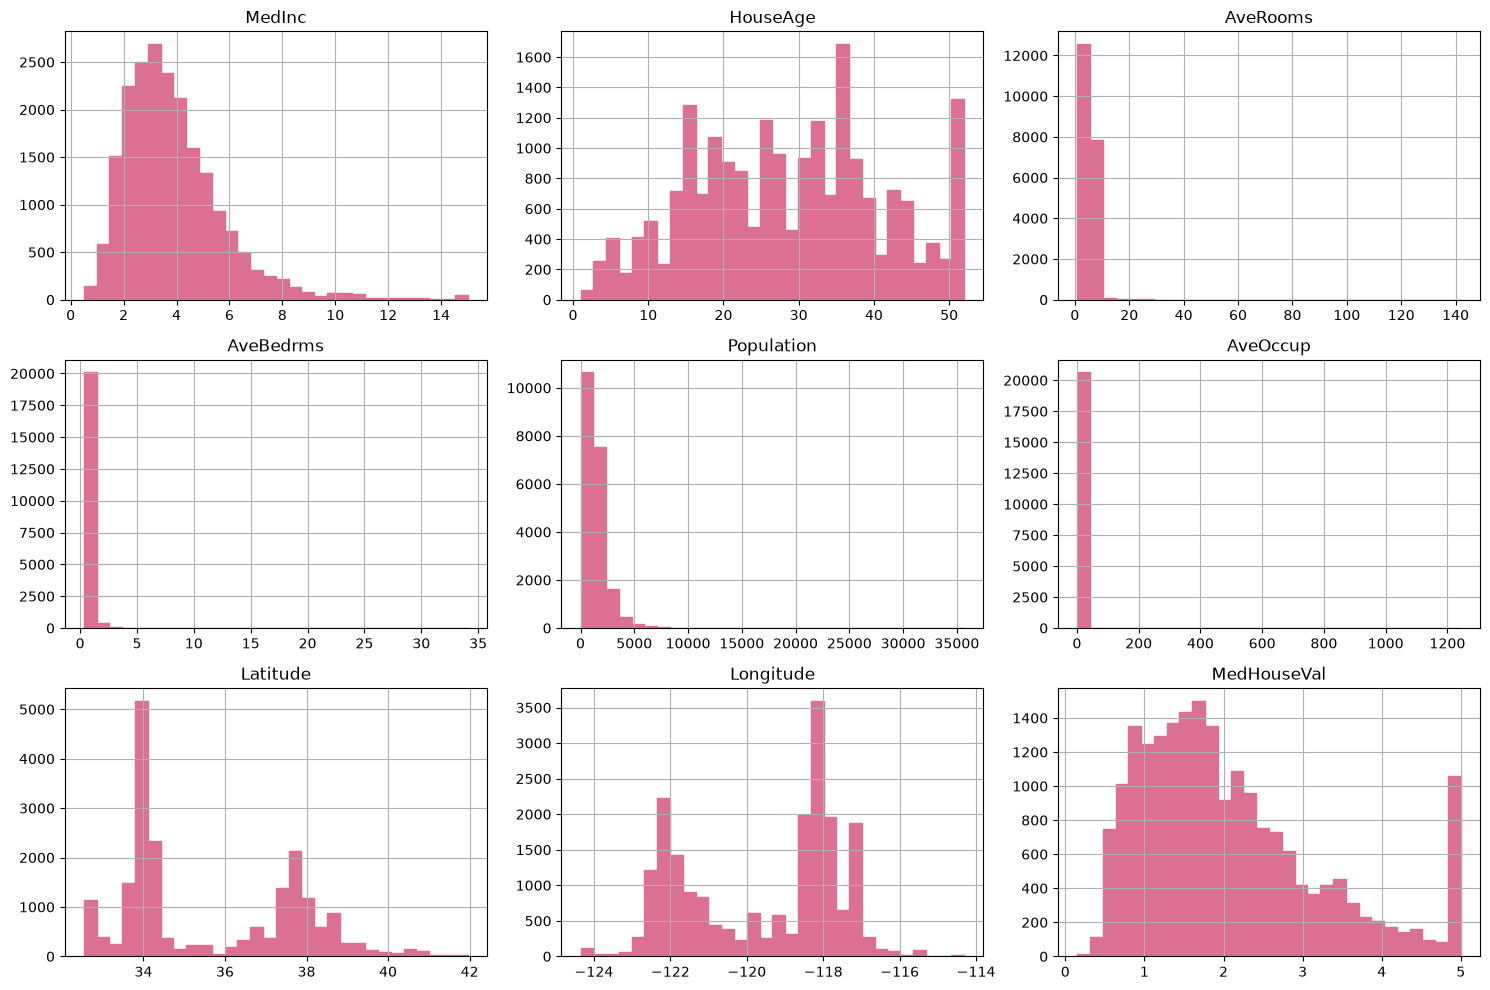

In [21]:
# Visualize the distribution of all variables
df.hist(
    bins=30,
    figsize=(15, 10),
    color="#DB7093",
    edgecolor="#DB7093"
)

plt.tight_layout()
plt.show()

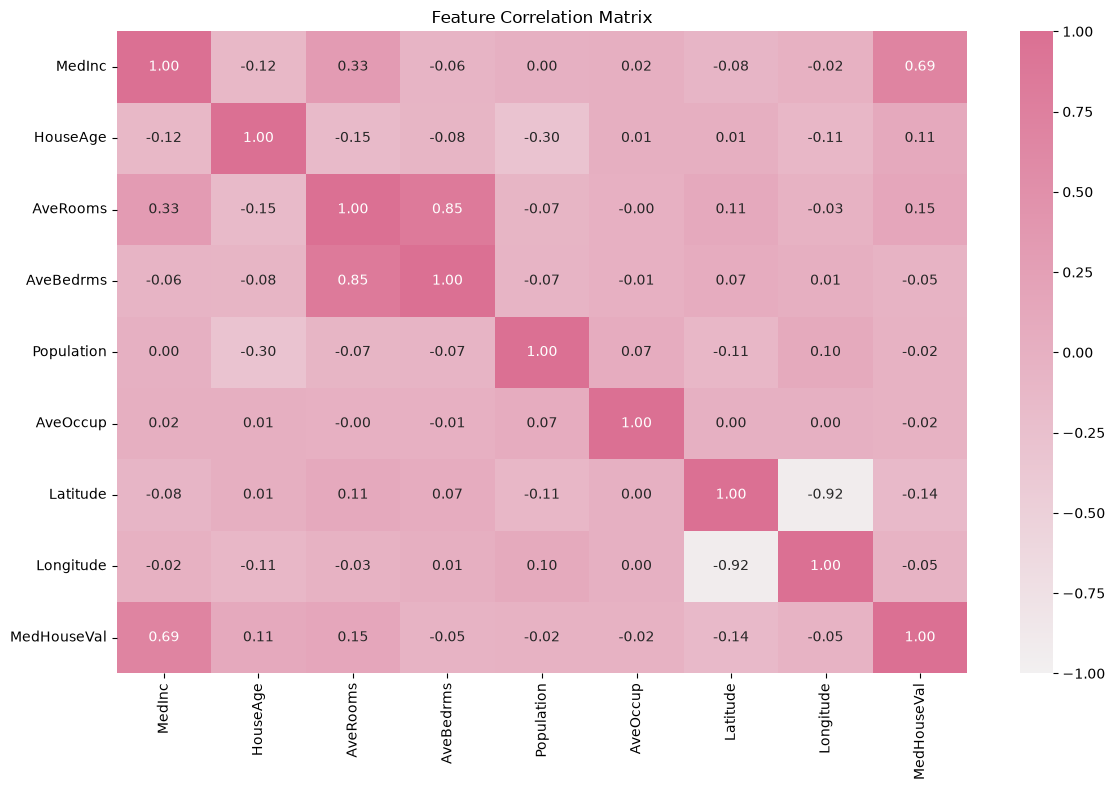

In [25]:
# Calculate the correlation matrix
correlation_matrix = df.corr()

# Visualize the correlation matrix
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap=sns.light_palette("#DB7093", as_cmap=True),
    fmt=".2f",
    vmin=-1,
    vmax=1,
    color="#DB7093"
)

plt.title("Feature Correlation Matrix")
plt.tight_layout()
plt.show()

In [26]:
# Calculate correlations with the target variable
target_correlation = (
    df.corr()["MedHouseVal"]
    .sort_values(ascending=False)
)

print(target_correlation)

MedHouseVal    1.000000
MedInc         0.688075
AveRooms       0.151948
HouseAge       0.105623
AveOccup      -0.023737
Population    -0.024650
Longitude     -0.045967
AveBedrms     -0.046701
Latitude      -0.144160
Name: MedHouseVal, dtype: float64


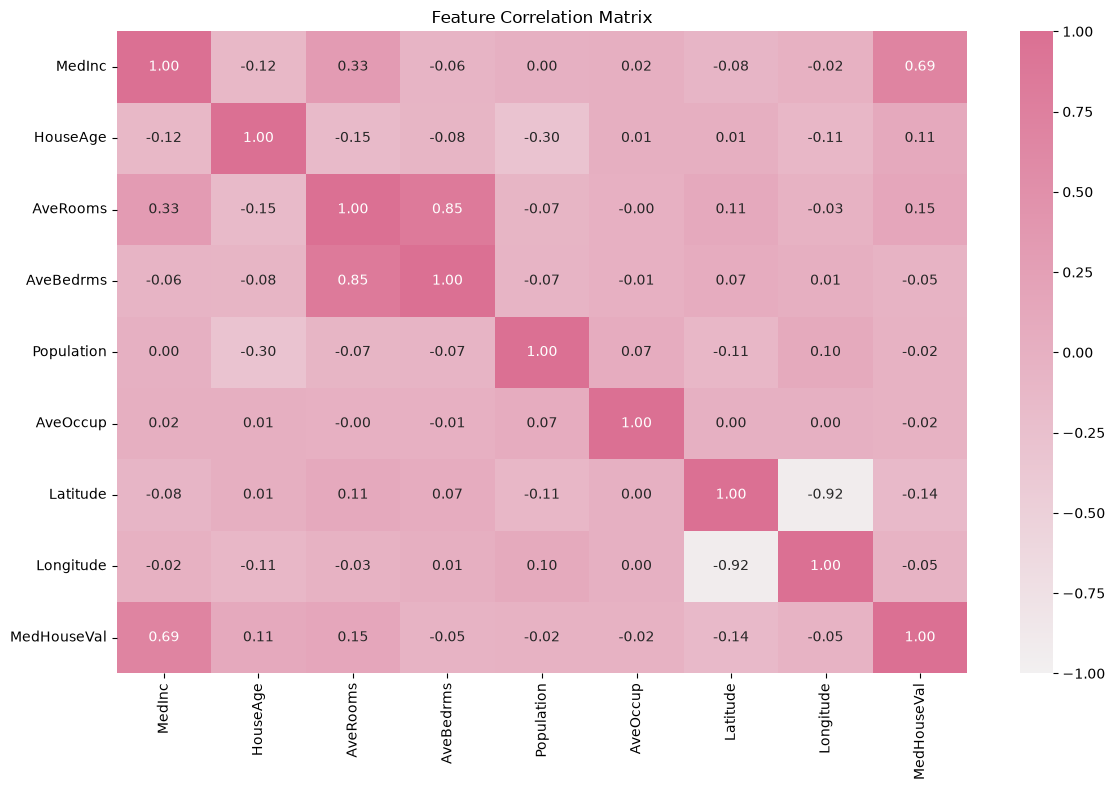

In [27]:
from pathlib import Path

# Locate the project root
project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

results_dir = project_root / "results"
results_dir.mkdir(exist_ok=True)

# Save the correlation matrix
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap=sns.light_palette("#DB7093", as_cmap=True),
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Feature Correlation Matrix")
plt.tight_layout()

plt.savefig(
    results_dir / "correlation_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 3. Data Preprocessing

In [28]:
# Separate features and target
X = df.drop(columns=["MedHouseVal"])
y = df["MedHouseVal"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (20640, 8)
Target shape: (20640,)


In [29]:
from sklearn.model_selection import train_test_split

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (16512, 8)
X_test: (4128, 8)
y_train: (16512,)
y_test: (4128,)


## 4. Linear Regression Model

In [30]:
from sklearn.linear_model import LinearRegression

# Initialize the model
lr_model = LinearRegression()

# Train the model
lr_model.fit(X_train, y_train)

print("Linear Regression training completed!")

Linear Regression training completed!


In [31]:
# Display the learned coefficients
coefficients = pd.DataFrame({
    "Feature": X_train.columns,
    "Coefficient": lr_model.coef_
})

print(coefficients)

print("\nIntercept:", lr_model.intercept_)

      Feature  Coefficient
0      MedInc     0.448675
1    HouseAge     0.009724
2    AveRooms    -0.123323
3   AveBedrms     0.783145
4  Population    -0.000002
5    AveOccup    -0.003526
6    Latitude    -0.419792
7   Longitude    -0.433708

Intercept: -37.02327770606413


In [32]:
# Make predictions on the test set
y_pred_lr = lr_model.predict(X_test)

print("Prediction shape:", y_pred_lr.shape)
print("First five predictions:", y_pred_lr[:5])

Prediction shape: (4128,)
First five predictions: [0.71912284 1.76401657 2.70965883 2.83892593 2.60465725]


In [33]:
# Compare actual and predicted house values
comparison = pd.DataFrame({
    "Actual": y_test.to_numpy(),
    "Predicted": y_pred_lr
})

comparison["Residual"] = (
    comparison["Actual"] - comparison["Predicted"]
)

comparison.head(10)

,Actual,Predicted,Residual
0,0.47700,0.719123,-0.242123
1,0.45800,1.764017,-1.306017
2,5.00001,2.709659,2.290351
3,2.18600,2.838926,-0.652926
4,2.78000,2.604657,0.175343
5,1.58700,2.011754,-0.424754
6,1.98200,2.645500,-0.663500
7,1.57500,2.168755,-0.593755
8,3.40000,2.740746,0.659254
9,4.46600,3.915615,0.550385


In [34]:
from sklearn.metrics import mean_squared_error

# Calculate MSE using Scikit-learn
mse_lr = mean_squared_error(y_test, y_pred_lr)

print("Scikit-learn MSE:", mse_lr)

Scikit-learn MSE: 0.5558915986952444


## 5. Random Forest Regression Model

In [35]:
from sklearn.ensemble import RandomForestRegressor

# Initialize the Random Forest model
rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=15,
    max_features="sqrt",
    random_state=42,
    n_jobs=-1
)

# Train the model
rf_model.fit(X_train, y_train)

print("Random Forest training completed!")

Random Forest training completed!


In [37]:
# Make predictions on the test set
y_pred_rf = rf_model.predict(X_test)

print("Prediction shape:", y_pred_rf.shape)
print("First five predictions:", y_pred_rf[:5])

Prediction shape: (4128,)
First five predictions: [0.52766267 0.92729011 4.8203001  2.45274367 2.24839726]


In [38]:
# Calculate Random Forest MSE
mse_rf = mean_squared_error(y_test, y_pred_rf)

print("Linear Regression MSE:", mse_lr)
print("Random Forest MSE:", mse_rf)

Linear Regression MSE: 0.5558915986952444
Random Forest MSE: 0.26111850317754653


In [42]:
# Calculate percentage improvement
improvement = (mse_lr - mse_rf) / mse_lr * 100

print(f"MSE reduction: {improvement:.2f}%")

MSE reduction: 53.03%


In [39]:
# Extract feature importance
feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_model.feature_importances_
}).sort_values(
    by="Importance",
    ascending=False
)

feature_importance

,Feature,Importance
0,MedInc,0.375753
6,Latitude,0.126610
7,Longitude,0.124555
2,AveRooms,0.123613
5,AveOccup,0.122871
1,HouseAge,0.055076
3,AveBedrms,0.040909
4,Population,0.030614


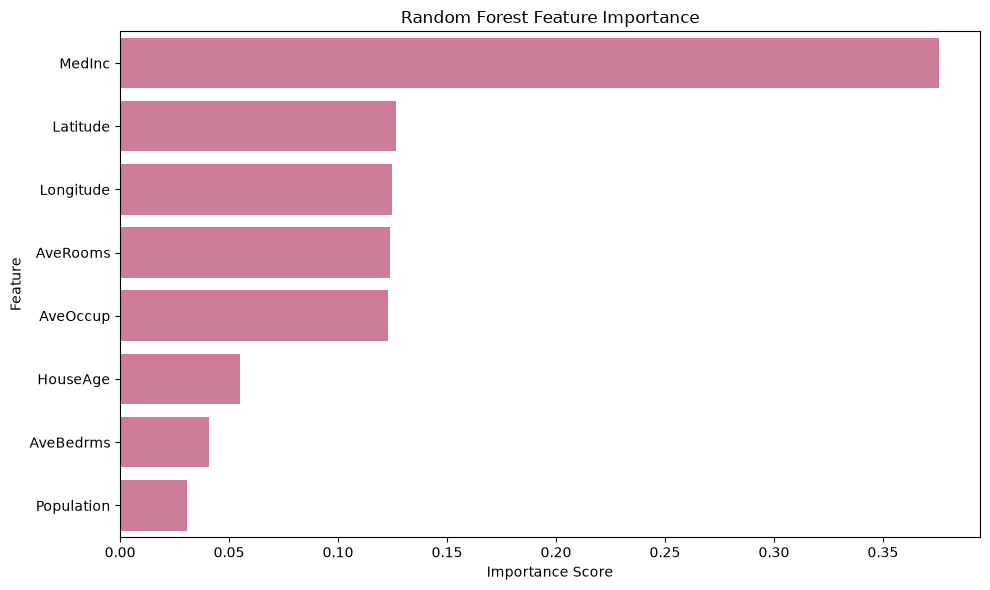

In [40]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance,
    x="Importance",
    y="Feature",
    color="#DB7093"
)

plt.title("Random Forest Feature Importance")
plt.xlabel("Importance Score")
plt.ylabel("Feature")

plt.tight_layout()

plt.savefig(
    results_dir / "feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [41]:
# Make predictions on the training set
y_train_pred_rf = rf_model.predict(X_train)

# Compare training and testing errors
train_mse_rf = mean_squared_error(
    y_train,
    y_train_pred_rf
)

print(f"Training MSE: {train_mse_rf:.4f}")
print(f"Testing MSE: {mse_rf:.4f}")

Training MSE: 0.0763
Testing MSE: 0.2611


## 6. Model Evaluation

In [43]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

def evaluate_model(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_pred)

    return {
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2": r2
    }

In [44]:
# Evaluate both models
lr_results = evaluate_model(y_test, y_pred_lr)
rf_results = evaluate_model(y_test, y_pred_rf)

# Create a comparison table
model_comparison = pd.DataFrame(
    [lr_results, rf_results],
    index=["Linear Regression", "Random Forest"]
)

model_comparison.round(4)

,MAE,MSE,RMSE,R2
Linear Regression,0.5332,0.5559,0.7456,0.5758
Random Forest,0.3444,0.2611,0.5110,0.8007


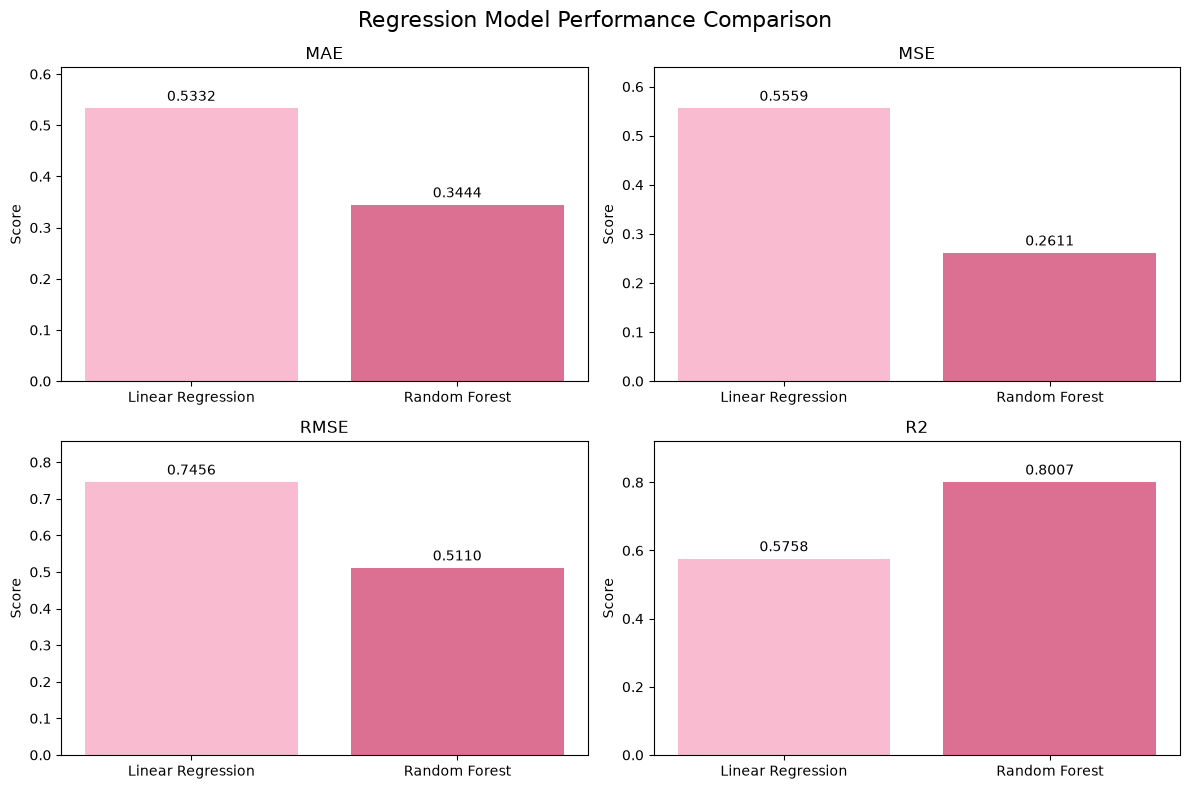

In [46]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

metrics = ["MAE", "MSE", "RMSE", "R2"]
colors = ["#F8BBD0", "#DB7093"]

for ax, metric in zip(axes.flatten(), metrics):

    bars = ax.bar(
        model_comparison.index,
        model_comparison[metric],
        color=colors
    )

    ax.set_title(metric)
    ax.set_ylabel("Score")
    ax.bar_label(bars, fmt="%.4f", padding=3)
    ax.margins(y=0.15)

plt.suptitle(
    "Regression Model Performance Comparison",
    fontsize=16
)

plt.tight_layout()

plt.savefig(
    results_dir / "model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

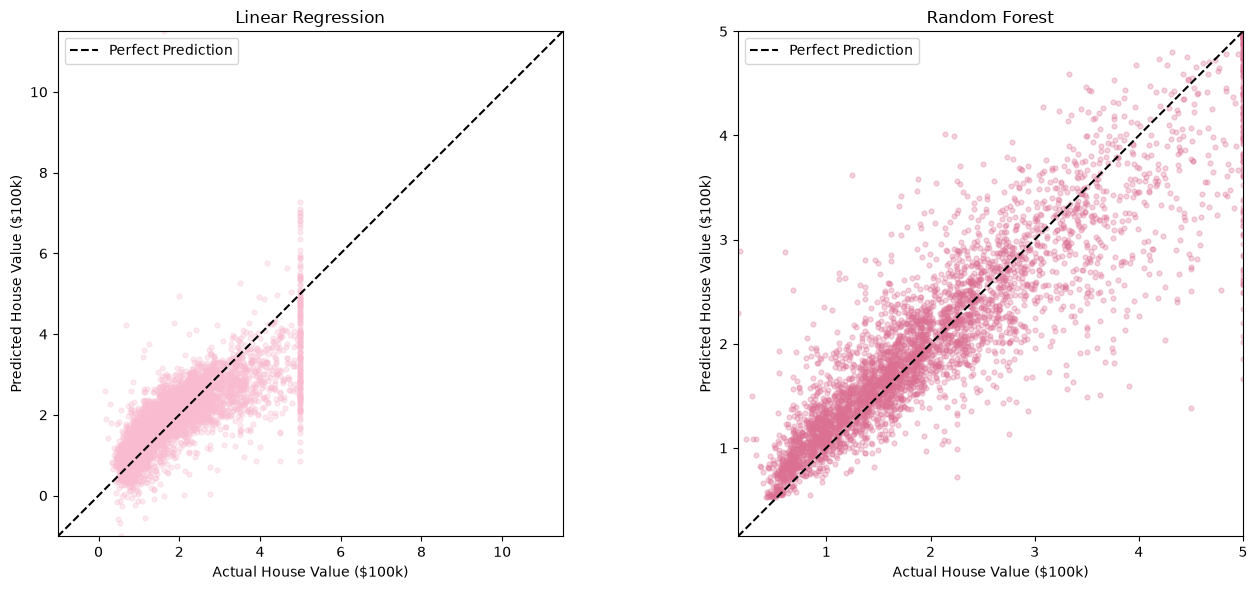

In [47]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

predictions = [y_pred_lr, y_pred_rf]
model_names = ["Linear Regression", "Random Forest"]

for ax, y_pred, name, color in zip(
    axes, predictions, model_names, colors
):

    ax.scatter(
        y_test,
        y_pred,
        alpha=0.3,
        s=12,
        color=color
    )

    lower = min(y_test.min(), y_pred.min())
    upper = max(y_test.max(), y_pred.max())

    ax.plot(
        [lower, upper],
        [lower, upper],
        "k--",
        label="Perfect Prediction"
    )

    ax.set_xlim(lower, upper)
    ax.set_ylim(lower, upper)
    ax.set_aspect("equal", adjustable="box")

    ax.set_xlabel("Actual House Value ($100k)")
    ax.set_ylabel("Predicted House Value ($100k)")
    ax.set_title(name)
    ax.legend()

plt.tight_layout()

plt.savefig(
    results_dir / "actual_vs_predicted.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

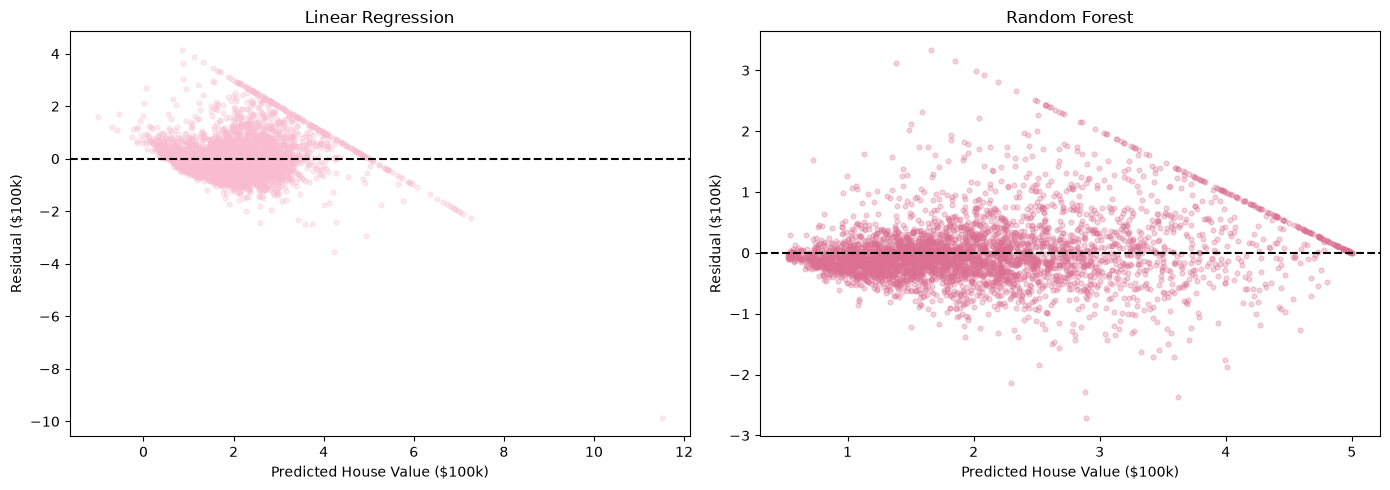

In [48]:
# Calculate residuals
residuals_lr = y_test.to_numpy() - y_pred_lr
residuals_rf = y_test.to_numpy() - y_pred_rf

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, y_pred, residuals, name, color in zip(
    axes,
    predictions,
    [residuals_lr, residuals_rf],
    model_names,
    colors
):

    ax.scatter(
        y_pred,
        residuals,
        alpha=0.3,
        s=12,
        color=color
    )

    ax.axhline(
        y=0,
        color="black",
        linestyle="--"
    )

    ax.set_xlabel("Predicted House Value ($100k)")
    ax.set_ylabel("Residual ($100k)")
    ax.set_title(name)

plt.tight_layout()

plt.savefig(
    results_dir / "residual_analysis.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [49]:
# Convert errors to US dollars
for name, row in model_comparison.iterrows():

    print(name)
    print(f"MAE:  ${row['MAE'] * 100000:,.2f}")
    print(f"RMSE: ${row['RMSE'] * 100000:,.2f}")
    print(f"R2:   {row['R2']:.4f}")
    print("-" * 40)

Linear Regression
MAE:  $53,320.01
RMSE: $74,558.14
R2:   0.5758
----------------------------------------
Random Forest
MAE:  $34,441.78
RMSE: $51,099.76
R2:   0.8007
----------------------------------------


## 7. Model Saving and Inference

In [50]:
import joblib

# Create the model directory
models_dir = project_root / "models"
models_dir.mkdir(exist_ok=True)

# Save trained models
joblib.dump(
    lr_model,
    models_dir / "linear_regression.joblib"
)

joblib.dump(
    rf_model,
    models_dir / "random_forest.joblib",
    compress=3
)

print("Models saved successfully!")

Models saved successfully!


In [51]:
# Load the saved Random Forest model
loaded_model = joblib.load(
    models_dir / "random_forest.joblib"
)

print("Model loaded successfully!")

Model loaded successfully!


In [52]:
# Create a new input sample
new_house = pd.DataFrame({
    "MedInc": [6.0],
    "HouseAge": [25.0],
    "AveRooms": [6.0],
    "AveBedrms": [1.1],
    "Population": [1500.0],
    "AveOccup": [3.0],
    "Latitude": [34.05],
    "Longitude": [-118.25]
})

# Predict the house value
prediction = loaded_model.predict(new_house)

# Convert the prediction to US dollars
predicted_price = prediction[0] * 100000

print(f"Predicted house value: ${predicted_price:,.2f}")

Predicted house value: $313,751.86


In [53]:
# Verify that the loaded model produces identical predictions
loaded_predictions = loaded_model.predict(X_test)

is_identical = np.allclose(
    y_pred_rf,
    loaded_predictions
)

print("Predictions are identical:", is_identical)

Predictions are identical: True


In [54]:
# Display saved model file sizes
for path in models_dir.glob("*.joblib"):

    size_mb = path.stat().st_size / (1024 ** 2)

    print(f"{path.name}: {size_mb:.2f} MB")

random_forest.joblib: 13.49 MB
linear_regression.joblib: 0.00 MB


In [55]:
model_comparison.to_csv(
    results_dir / "model_comparison.csv"
)